# **UTS Analisis Bisnis dan data perusahaan**
## Judul project : Analisis Produk Tokopedia untuk Mendukung Strategi Pemasaran
**Mata Kuliah : Analisis Bisnis dan data perusahaan**

**Dosen Pengampu : Murahartawaty, S.T., M.T., Ph.D.**

**Oleh : Silvia Nabela (202022610005)**

**Tujuan analisis:** memahami karakteristik produk, mengidentifikasi hubungan harga diskon, rating, ulasan dengan penjualan, mengelompokkan produk, membuat estimasi penjualan, dan menyusun rekomendasi strategi.

**Kerangka kerja:** KDD (Selection → Preprocessing → Transformation → Data Mining → Interpretation/Evaluation).


## Peta alur pengerjaan

| Tahap | Proses | Hasil |
|---|---|---|
| 1 | Membaca data mentah | Memahami ukuran, kolom, contoh data |
| 2 | Audit kualitas data | Missing value, duplikat, tipe data, nilai tidak wajar |
| 3 | Cleaning | Konversi teks ke angka, validasi, penanganan missing |
| 4 | Simpan dan unduh data bersih | CSV hasil cleaning |
| 5 | Baca ulang data bersih | Memastikan analisis memakai file final |
| 6 | Deskriptif | Histogram harga dan Top 10 produk |
| 7 | Diagnostik | Heatmap dan scatter plot diskon vs penjualan |
| 8 | Prediktif dan segmentasi | Random Forest Regression dan K-Means |
| 9 | Preskriptif | Keputusan berdasarkan hasil model |
| 10 | Ekspor | Dataset dan tabel untuk infografis/Looker Studio |

1. Membaca dataset awal

In [15]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score

)
from IPython.display import display
from google.colab import drive, files
drive.mount('/content/drive')
# Palet warna Tokopedia
TOKO_GREEN = "#03AC0E"
TOKO_DARK = "#008A0E"
TOKO_LIGHT = "#7ED957"
TOKO_PALE = "#E8F5E9"
TOKO_GRAY = "#64748B"

# Palet hijau bertingkat
TOKO_PALETTE = [
    "#008A0E",
    "#03AC0E",
    "#35C759",
    "#7ED957",
    "#B7E4A8",
    "#E8F5E9"
]

# Pengaturan default visualisasi
sns.set_theme(style="whitegrid")

plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=TOKO_PALETTE
)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.edgecolor"] = "#D9E2D9"
plt.rcParams["grid.color"] = "#E5EDE5"
plt.rcParams["text.color"] = "#263238"
plt.rcParams["axes.labelcolor"] = "#263238"
plt.rcParams["xtick.color"] = "#263238"
plt.rcParams["ytick.color"] = "#263238"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 50)

Mounted at /content/drive


In [17]:
folder_path = '/content/drive/MyDrive/UTS_DATA_ANALYTICS'
file_path = os.path.join(folder_path, 'produk_tokopedia.csv')

# Membuat folder jika belum tersedia
os.makedirs(folder_path, exist_ok=True)

if not os.path.exists(file_path):

    print("Dataset belum ditemukan di Google Drive.")
    print("Silakan upload file produk_tokopedia.csv")

    uploaded = files.upload()

    for filename in uploaded.keys():
        destination = os.path.join(folder_path, filename)
        shutil.copy2(filename, destination)

        if filename == 'produk_tokopedia.csv':
            file_path = destination

# Memastikan file tersedia
if not os.path.exists(file_path):
    raise FileNotFoundError(
        "File produk_tokopedia.csv tidak ditemukan. "
        "Periksa nama dan lokasi file di Google Drive."
    )

print("\nDataset berhasil ditemukan!")
print("Lokasi file:", file_path)

df_raw = pd.read_csv(
    file_path,
    sep=';',
    engine='python'
)


print("Jumlah baris dan kolom:", df_raw.shape)

print("\nNama kolom:")
print(df_raw.columns.tolist())

print("\nLima baris pertama:")
display(df_raw.head())

print("\nInformasi tipe data:")
df_raw.info()



Dataset berhasil ditemukan!
Lokasi file: /content/drive/MyDrive/UTS_DATA_ANALYTICS/produk_tokopedia.csv
Jumlah baris dan kolom: (29519, 17)

Nama kolom:
['Nama Produk', 'Nama Toko', 'Lokasi Toko', 'Terjual', 'Jumlah Ulasan', 'Rating', 'Harga (IDR)', 'Diskon (%)', 'Produk URL', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']

Lima baris pertama:


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1rb+ terjual,10 ulasan,5.0,35000,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-food-beef-bone-in-daging-giling-dog-food-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250+ terjual,NaN,5.0,79999,0.0,https://www.tokopedia.com/rumahbully/turkey-meat-only-no-bone-1kg-daging-kalkun-raw-dog-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26 terjual,NaN,5.0,33000,0.0,https://www.tokopedia.com/rumahbully/chicken-mix-salmon-raw-food-ayam-mix-salmon-makanan-kucing-...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100+ terjual,NaN,5.0,29900,0.0,https://www.tokopedia.com/rumahbully/promo-bulanan-sosis-chop-premium-raw-dog-food-1kg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1rb+ terjual,NaN,5.0,39000,0.0,https://www.tokopedia.com/rumahbully/premium-dog-food-daging-sapi-giling-raw-food-beef-bone-in-p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29519 entries, 0 to 29518
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Nama Produk    29519 non-null  object
 1   Nama Toko      29466 non-null  object
 2   Lokasi Toko    29380 non-null  object
 3   Terjual        29293 non-null  object
 4   Jumlah Ulasan  28294 non-null  object
 5   Rating         29488 non-null  object
 6   Harga (IDR)    29506 non-null  object
 7   Diskon (%)     29509 non-null  object
 8   Produk URL     29515 non-null  object
 9   Unnamed: 9     964 non-null    object
 10  Unnamed: 10    291 non-null    object
 11  Unnamed: 11    113 non-null    object
 12  Unnamed: 12    42 non-null     object
 13  Unnamed: 13    20 non-null     object
 14  Unnamed: 14    7 non-null      object
 15  Unnamed: 15    3 non-null      object
 16  Unnamed: 16    1 non-null      object
dtypes: object(17)
memory usage: 3.8+ MB


#2. Kualitas data sebelum cleaning
Memeriksa masalahnya seperti memeriksa tipe data, missing value, duplikat, nilai unik, dan contoh data.

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29519 entries, 0 to 29518
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Nama Produk    29519 non-null  object
 1   Nama Toko      29466 non-null  object
 2   Lokasi Toko    29380 non-null  object
 3   Terjual        29293 non-null  object
 4   Jumlah Ulasan  28294 non-null  object
 5   Rating         29488 non-null  object
 6   Harga (IDR)    29506 non-null  object
 7   Diskon (%)     29509 non-null  object
 8   Produk URL     29515 non-null  object
 9   Unnamed: 9     964 non-null    object
 10  Unnamed: 10    291 non-null    object
 11  Unnamed: 11    113 non-null    object
 12  Unnamed: 12    42 non-null     object
 13  Unnamed: 13    20 non-null     object
 14  Unnamed: 14    7 non-null      object
 15  Unnamed: 15    3 non-null      object
 16  Unnamed: 16    1 non-null      object
dtypes: object(17)
memory usage: 3.8+ MB


In [ ]:
audit_missing_awal = pd.DataFrame({
    "Jumlah Missing": df_raw.isna().sum(),
    "Persentase Missing (%)": (df_raw.isna().mean() * 100).round(2),
    "Tipe Data": df_raw.dtypes.astype(str)
}).sort_values("Jumlah Missing", ascending=False)

display(audit_missing_awal)

,Jumlah Missing,Persentase Missing (%),Tipe Data
Unnamed: 16,29518,100.00,object
Unnamed: 15,29516,99.99,object
Unnamed: 14,29512,99.98,object
Unnamed: 13,29499,99.93,object
Unnamed: 12,29477,99.86,object
Unnamed: 11,29406,99.62,object
Unnamed: 10,29228,99.01,object
Unnamed: 9,28555,96.73,object
Jumlah Ulasan,1225,4.15,object
Terjual,226,0.77,object


In [ ]:
print("Jumlah baris duplikat:", df_raw.duplicated().sum())
print("Jumlah baris:", len(df_raw))

Jumlah baris duplikat: 414
Jumlah baris: 29519


In [ ]:
kolom_utama = [
    "Nama Produk", "Nama Toko", "Lokasi Toko",
    "Terjual", "Jumlah Ulasan", "Rating",
    "Harga (IDR)", "Diskon (%)"
]

display(df_raw[kolom_utama].head(15))

,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%)
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1rb+ terjual,10 ulasan,5.0,35000,0.0
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250+ terjual,NaN,5.0,79999,0.0
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26 terjual,NaN,5.0,33000,0.0
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100+ terjual,NaN,5.0,29900,0.0
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1rb+ terjual,NaN,5.0,39000,0.0
5,Complete Dog Raw food With offal & Vegetable - BEST LAMB - (1KG),RumahBully,Tangerang Selatan,100+ terjual,NaN,5.0,79999,0.0
6,Dog & Cat Raw Food - Fresh Turkey BARF 1kg,RumahBully,Jakarta Timur,4rb+ terjual,NaN,4.9,45000,0.0
7,RAW FOOD CHICKEN/CAT FOOD/ DOG FOOD/MAKANAN KUCING/MAKANAN ANJING 1KG,RumahBully,Jakarta Barat,1rb+ terjual,NaN,4.9,8000,0.0
8,Papillon Makanan Anjing RAW Food Dog Food Anjing - Chicken Berries 1kg,Papillon,Jakarta Utara,500+ terjual,NaN,4.9,71250,5.0
9,Paket Turkey Meat ONLY - Super Hemat ( 14KG =Rp.1Jt) Dog Cat Raw Food,RumahBully,Jakarta Timur,30+ Terjual,29 ulasan,5.0,1000000,0.0


In [ ]:
kolom_unnamed = [c for c in df_raw.columns if str(c).startswith("Unnamed")]

if kolom_unnamed:
    print("Kolom tambahan:", kolom_unnamed)
    display(df_raw[kolom_unnamed].isna().sum().to_frame("Jumlah Kosong"))
else:
    print("Tidak ada kolom Unnamed.")

Kolom tambahan: ['Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']


,Jumlah Kosong
Unnamed: 9,28555
Unnamed: 10,29228
Unnamed: 11,29406
Unnamed: 12,29477
Unnamed: 13,29499
Unnamed: 14,29512
Unnamed: 15,29516
Unnamed: 16,29518


# 3. Selection (KDD)

Kita memilih kolom yang diperlukan

In [ ]:
kolom_dipakai = [
    "Nama Produk",
    "Nama Toko",
    "Lokasi Toko",
    "Terjual",
    "Jumlah Ulasan",
    "Rating",
    "Harga (IDR)",
    "Diskon (%)",
    "Produk URL"
]

kolom_tidak_ada = [c for c in kolom_dipakai if c not in df_raw.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}")

df = df_raw[kolom_dipakai].copy()

print("Ukuran setelah pemilihan kolom:", df.shape)

Ukuran setelah pemilihan kolom: (29519, 9)


In [ ]:
#Menghapus duplikat
jumlah_duplikat = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Duplikat yang dihapus:", jumlah_duplikat)
print("Ukuran setelah menghapus duplikat:", df.shape)

Duplikat yang dihapus: 416
Ukuran setelah menghapus duplikat: (29103, 9)


# 5. Preprocessing


In [18]:
#Membuat fungsi konversi jumlah terjual dan jumlah ulasan
def parse_quantity(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip().replace(",", ".")
    if text == "":
        return np.nan

    match = re.search(r"(\d+(?:\.\d+)?)\s*(rb|ribu|jt|juta)?", text)
    if not match:
        return np.nan

    number = float(match.group(1))
    unit = match.group(2)

    if unit in ["rb", "ribu"]:
        number *= 1000
    elif unit in ["jt", "juta"]:
        number *= 1000000

    return number

contoh = ["1rb+ terjual", "250+ terjual", "26 terjual", "1,3 rb ulasan", "10 ulasan"]
for item in contoh:
    print(item, "=>", parse_quantity(item))

1rb+ terjual => 1000.0
250+ terjual => 250.0
26 terjual => 26.0
1,3 rb ulasan => 1300.0
10 ulasan => 10.0


In [20]:
#Membuat fungsi konversi kolom harga, rating, dan diskon
def parse_numeric(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()
    if text == "":
        return np.nan

    text = re.sub(r"[^0-9,.-]", "", text)
    if text == "":
        return np.nan

    # Menangani format desimal koma.
    if "," in text and "." not in text:
        text = text.replace(",", ".")
    elif "," in text and "." in text:
        # Jika keduanya ada, koma diasumsikan pemisah ribuan.
        text = text.replace(",", "")

    try:
        return float(text)
    except ValueError:
        return np.nan

In [24]:
import pandas as pd
import numpy as np
import re

def parse_quantity(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    if text in ["", "-", ".", "nan", "none"]:
        return np.nan

    multiplier = 1

    if "jt" in text:
        multiplier = 1_000_000
        text = text.replace("jt", "")
    elif "rb" in text:
        multiplier = 1_000
        text = text.replace("rb", "")
    elif "k" in text:
        multiplier = 1_000
        text = text.replace("k", "")

    text = text.replace(",", ".")

    # Mengambil angka yang valid
    match = re.search(r"\d+(?:\.\d+)?", text)

    if not match:
        return np.nan

    number = float(match.group())

    return number * multiplier

In [25]:
# Membuat salinan dataset mentah
df = df_raw.copy()

# Menyimpan teks asli
df["Terjual_Teks_Asli"] = df["Terjual"].copy()
df["Ulasan_Teks_Asli"] = df["Jumlah Ulasan"].copy()

# Mengonversi jumlah penjualan dan ulasan
df["Terjual"] = df["Terjual"].apply(parse_quantity)
df["Jumlah Ulasan"] = df["Jumlah Ulasan"].apply(parse_quantity)

# Mengonversi harga, rating, dan diskon
for col in ["Harga (IDR)", "Rating", "Diskon (%)"]:
    df[col] = df[col].apply(parse_numeric)

print("Tipe data setelah konversi:")

display(
    df[
        ["Harga (IDR)", "Terjual", "Jumlah Ulasan",
         "Rating", "Diskon (%)"]
    ].dtypes.to_frame("Tipe Data")
)

print("\nPerbandingan teks asli dan hasil konversi:")

display(
    df[
        ["Terjual_Teks_Asli", "Terjual",
         "Ulasan_Teks_Asli", "Jumlah Ulasan"]
    ].head(10)
)

Tipe data setelah konversi:


,Tipe Data
Harga (IDR),float64
Terjual,float64
Jumlah Ulasan,float64
Rating,float64
Diskon (%),float64



Perbandingan teks asli dan hasil konversi:


,Terjual_Teks_Asli,Terjual,Ulasan_Teks_Asli,Jumlah Ulasan
0,1rb+ terjual,1000.0,10 ulasan,10.0
1,250+ terjual,250.0,NaN,NaN
2,26 terjual,26.0,NaN,NaN
3,100+ terjual,100.0,NaN,NaN
4,1rb+ terjual,1000.0,NaN,NaN
5,100+ terjual,100.0,NaN,NaN
6,4rb+ terjual,4000.0,NaN,NaN
7,1rb+ terjual,1000.0,NaN,NaN
8,500+ terjual,500.0,NaN,NaN
9,30+ Terjual,30.0,29 ulasan,29.0


# 6. Validasi dan penanganan missing value

In [ ]:
# Validasi rentang nilai
df.loc[df["Harga (IDR)"] <= 0, "Harga (IDR)"] = np.nan
df.loc[~df["Rating"].between(0, 5), "Rating"] = np.nan
df.loc[~df["Diskon (%)"].between(0, 100), "Diskon (%)"] = np.nan
df.loc[df["Terjual"] < 0, "Terjual"] = np.nan
df.loc[df["Jumlah Ulasan"] < 0, "Jumlah Ulasan"] = np.nan

print("Validasi rentang selesai.")

Validasi rentang selesai.


In [ ]:
# Mendeteksi baris dengan isi Terjual yang tidak bisa dikonversi
sales_text_invalid = (
    df["Terjual_Teks_Asli"].notna()
    & df["Terjual"].isna()
)

print("Baris dengan isi Terjual nonkosong tetapi gagal dikonversi:",
      int(sales_text_invalid.sum()))
df_baris_tidak_valid = df.loc[sales_text_invalid].copy()

df = df.loc[~sales_text_invalid].copy()

print("Ukuran setelah mengeluarkan baris tidak konsisten:", df.shape)

Baris dengan isi Terjual nonkosong tetapi gagal dikonversi: 1040
Ukuran setelah mengeluarkan baris tidak konsisten: (28063, 11)


In [ ]:
#Menangani kolom kategori dan nama produk
# Nama produk kosong tidak dapat dipakai untuk identifikasi produk.
jumlah_nama_kosong = df["Nama Produk"].isna().sum()
df = df.dropna(subset=["Nama Produk"]).copy()

# Nama toko/lokasi kosong diberi label agar baris tetap bisa dipakai
# untuk analisis yang tidak membutuhkan identitas toko/lokasi.
df["Nama Toko"] = df["Nama Toko"].fillna("Tidak diketahui")
df["Lokasi Toko"] = df["Lokasi Toko"].fillna("Tidak diketahui")

print("Nama produk kosong yang dihapus:", int(jumlah_nama_kosong))
print("Ukuran setelah penanganan nama:", df.shape)

Nama produk kosong yang dihapus: 0
Ukuran setelah penanganan nama: (28063, 11)


In [ ]:
#missing value setelah validasi
kolom_numerik = [
    "Harga (IDR)", "Terjual", "Jumlah Ulasan", "Rating", "Diskon (%)"
]

audit_setelah_validasi = pd.DataFrame({
    "Missing": df[kolom_numerik].isna().sum(),
    "Missing (%)": (df[kolom_numerik].isna().mean() * 100).round(2),
    "Median": df[kolom_numerik].median(),
    "Minimum": df[kolom_numerik].min(),
    "Maksimum": df[kolom_numerik].max()
})

display(audit_setelah_validasi)

,Missing,Missing (%),Median,Minimum,Maksimum
Harga (IDR),43,0.15,99000.0,1.0,900000000.0
Terjual,225,0.80,40.0,0.0,1000000.0
Jumlah Ulasan,1574,5.61,10.0,0.0,1000000.0
Rating,48,0.17,5.0,0.0,5.0
Diskon (%),12,0.04,0.0,0.0,100.0


**tidak semua missing value diisi** Karena penjualan yang tidak tercatat tidak boleh dianggap nol. Harga yang hilang juga tidak boleh diganti rata-rata untuk grafik harga karena itu akan menciptakan observasi harga yang tidak pernah tercatat.

In [28]:
kolom_dipakai = [
    "Nama Produk",
    "Nama Toko",
    "Lokasi Toko",
    "Terjual",
    "Jumlah Ulasan",
    "Rating",
    "Harga (IDR)",
    "Diskon (%)",
    "Produk URL"
]

print("Jumlah kolom yang dipilih:", len(kolom_dipakai))

Jumlah kolom yang dipilih: 9


In [29]:
# Ringkasan jumlah data di setiap tahap

ringkasan_jumlah_data = pd.DataFrame({
    "Tahap": [
        "Data mentah",
        "Setelah memilih kolom",
        "Setelah menghapus duplikat",
        "Setelah mengeluarkan baris Terjual tidak valid",
        "Setelah menghapus nama produk kosong"
    ],
    "Jumlah Baris": [
        len(df_raw),
        len(df_raw[kolom_dipakai]),
        len(df_raw[kolom_dipakai].drop_duplicates()),
        len(df),
        len(df)
    ]
})

display(ringkasan_jumlah_data)

,Tahap,Jumlah Baris
0,Data mentah,29519
1,Setelah memilih kolom,29519
2,Setelah menghapus duplikat,29103
3,Setelah mengeluarkan baris Terjual tidak valid,29519
4,Setelah menghapus nama produk kosong,29519


#7. Menyimpan dan mengunduh dataset hasil cleaning


In [31]:
# Membuat ulang data hasil konversi dari data mentah
df_sementara = df_raw[kolom_dipakai].drop_duplicates().copy()

# Simpan teks penjualan asli
df_sementara["Terjual_Teks_Asli"] = df_sementara["Terjual"].copy()

# Konversi penjualan
df_sementara["Terjual"] = df_sementara["Terjual"].apply(parse_quantity)

# Identifikasi baris yang tidak valid
sales_text_invalid = (
    df_sementara["Terjual_Teks_Asli"].notna()
    & df_sementara["Terjual"].isna()
)

df_baris_tidak_valid = df_sementara.loc[
    sales_text_invalid
].copy()

print("Jumlah baris tidak valid:", len(df_baris_tidak_valid))

Jumlah baris tidak valid: 1040


In [48]:
clean_path = '/content/drive/MyDrive/UTS_DATA_ANALYTICS/tokopedia_cleaned.csv'

invalid_path = '/content/drive/MyDrive/UTS_DATA_ANALYTICS/tokopedia_baris_tidak_valid.csv'

df.to_csv(clean_path, index=False)

df_baris_tidak_valid.to_csv(
    invalid_path,
    index=False
)

print("Dataset bersih berhasil disimpan!")
print("Jumlah data bersih:", len(df))

print("Data tidak valid berhasil disimpan!")
print("Jumlah data tidak valid:", len(df_baris_tidak_valid))

Dataset bersih berhasil disimpan!
Jumlah data bersih: 29519
Data tidak valid berhasil disimpan!
Jumlah data tidak valid: 1040


Karena datanya ada yang masih kosong, maka saya lakukan pengecekan ulang

In [42]:
print("Jumlah data df_raw:", df_raw.shape)

print("Jumlah data df:", df.shape)

print("Jumlah data df_clean:", df_clean.shape)

print("\nKolom df_clean:")
print(df_clean.columns.tolist())

Jumlah data df_raw: (29519, 17)
Jumlah data df: (29519, 19)
Jumlah data df_clean: (29519, 19)

Kolom df_clean:
['Nama Produk', 'Nama Toko', 'Lokasi Toko', 'Terjual', 'Jumlah Ulasan', 'Rating', 'Harga (IDR)', 'Diskon (%)', 'Produk URL', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Terjual_Teks_Asli', 'Ulasan_Teks_Asli']


karna masih ada data mentah dan kolom tambahan jadi kita buat ulang dengan membersihkan yang diperlukan

In [46]:

kolom_dipakai = [
    "Nama Produk", "Nama Toko", "Lokasi Toko",
    "Terjual", "Jumlah Ulasan", "Rating",
    "Harga (IDR)", "Diskon (%)", "Produk URL"
]

df_clean = df_raw[kolom_dipakai].copy()

jumlah_awal = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
jumlah_duplikat = jumlah_awal - len(df_clean)

def parse_quantity(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    if text in ["", ".", "-", "nan", "none"]:
        return np.nan

    multiplier = 1

    if "rb" in text or "ribu" in text:
        multiplier = 1000
    elif "jt" in text or "juta" in text:
        multiplier = 1000000

    text = re.sub(r"(rb|ribu|jt|juta|\+)", "", text)
    text = re.sub(r"[^0-9,\.]", "", text)

    if not text:
        return np.nan

    if "." in text and "," not in text:
        text = text.replace(".", "")
    elif "," in text and "." not in text:
        text = text.replace(",", ".")

    try:
        return float(text) * multiplier
    except ValueError:
        return np.nan

def parse_numeric(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()

    if text in ["", ".", "-", "nan", "None"]:
        return np.nan

    text = re.sub(r"[^0-9,\.]", "", text)

    if not text:
        return np.nan

    if "," in text and "." not in text:
        text = text.replace(",", ".")

    try:
        return float(text)
    except ValueError:
        return np.nan
df_clean["Terjual_Teks_Asli"] = df_clean["Terjual"].copy()
df_clean["Ulasan_Teks_Asli"] = df_clean["Jumlah Ulasan"].copy()

df_clean["Terjual"] = df_clean["Terjual"].apply(parse_quantity)
df_clean["Jumlah Ulasan"] = df_clean["Jumlah Ulasan"].apply(parse_quantity)

for col in ["Harga (IDR)", "Rating", "Diskon (%)"]:
    df_clean[col] = df_clean[col].apply(parse_numeric)

df_clean.loc[df_clean["Harga (IDR)"] <= 0, "Harga (IDR)"] = np.nan
df_clean.loc[~df_clean["Rating"].between(0, 5), "Rating"] = np.nan
df_clean.loc[~df_clean["Diskon (%)"].between(0, 100), "Diskon (%)"] = np.nan
df_clean.loc[df_clean["Terjual"] < 0, "Terjual"] = np.nan
df_clean.loc[df_clean["Jumlah Ulasan"] < 0, "Jumlah Ulasan"] = np.nan

baris_tidak_valid = (
    df_clean["Terjual_Teks_Asli"].notna()
    & df_clean["Terjual"].isna()
)

df_baris_tidak_valid = df_clean.loc[baris_tidak_valid].copy()
df_clean = df_clean.loc[~baris_tidak_valid].copy()

df_clean = df_clean.dropna(subset=["Nama Produk"]).copy()

df_clean["Nama Toko"] = df_clean["Nama Toko"].fillna("Tidak diketahui")
df_clean["Lokasi Toko"] = df_clean["Lokasi Toko"].fillna("Tidak diketahui")


print("HASIL CLEANING")
print("Data mentah:", df_raw.shape)
print("Duplikat dihapus:", jumlah_duplikat)
print("Baris penjualan tidak valid:", len(df_baris_tidak_valid))
print("Data setelah cleaning:", df_clean.shape)

print("\nMISSING VALUE SETELAH CLEANING")
display(df_clean.isnull().sum().to_frame("Jumlah Missing"))

print("\nLIMA DATA BERSIH")
display(df_clean.head())

HASIL CLEANING
Data mentah: (29519, 17)
Duplikat dihapus: 416
Baris penjualan tidak valid: 1040
Data setelah cleaning: (28063, 11)

MISSING VALUE SETELAH CLEANING


,Jumlah Missing
Nama Produk,0
Nama Toko,0
Lokasi Toko,0
Terjual,225
Jumlah Ulasan,1574
Rating,48
Harga (IDR),43
Diskon (%),12
Produk URL,4
Terjual_Teks_Asli,225



LIMA DATA BERSIH


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL,Terjual_Teks_Asli,Ulasan_Teks_Asli
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1000.0,10.0,5.0,35000.0,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-food-beef-bone-in-daging-giling-dog-food-cat-food,1rb+ terjual,10 ulasan
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250.0,NaN,5.0,79999.0,0.0,https://www.tokopedia.com/rumahbully/turkey-meat-only-no-bone-1kg-daging-kalkun-raw-dog-cat-food,250+ terjual,NaN
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26.0,NaN,5.0,33000.0,0.0,https://www.tokopedia.com/rumahbully/chicken-mix-salmon-raw-food-ayam-mix-salmon-makanan-kucing-...,26 terjual,NaN
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100.0,NaN,5.0,29900.0,0.0,https://www.tokopedia.com/rumahbully/promo-bulanan-sosis-chop-premium-raw-dog-food-1kg,100+ terjual,NaN
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1000.0,NaN,5.0,39000.0,0.0,https://www.tokopedia.com/rumahbully/premium-dog-food-daging-sapi-giling-raw-food-beef-bone-in-p...,1rb+ terjual,NaN


karena datasetnya masih ada yang kosong, maka coba diisi dengan median

In [51]:
# 1. Membuat salinan dataset bersih
df_imputed = df_clean.copy()

# 2. Kolom prediktor yang akan diisi menggunakan median
kolom_imputasi = [
    "Harga (IDR)",
    "Jumlah Ulasan",
    "Rating",
    "Diskon (%)"
]

# 3. Mengisi missing value menggunakan median
for kolom in kolom_imputasi:
    median_value = df_imputed[kolom].median()
    df_imputed[kolom] = df_imputed[kolom].fillna(median_value)

# 4. Memeriksa hasil imputasi
print("MISSING VALUE SETELAH IMPUTASI")
display(df_imputed.isnull().sum().to_frame("Jumlah Missing"))

print("\nUkuran dataset:")
print(df_imputed.shape)

print("\nLima data pertama:")
display(df_imputed.head())

MISSING VALUE SETELAH IMPUTASI


,Jumlah Missing
Nama Produk,0
Nama Toko,0
Lokasi Toko,0
Terjual,225
Jumlah Ulasan,0
Rating,0
Harga (IDR),0
Diskon (%),0
Produk URL,4
Terjual_Teks_Asli,225



Ukuran dataset:
(28063, 11)

Lima data pertama:


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL,Terjual_Teks_Asli,Ulasan_Teks_Asli
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1000.0,10.0,5.0,35000.0,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-food-beef-bone-in-daging-giling-dog-food-cat-food,1rb+ terjual,10 ulasan
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250.0,10.0,5.0,79999.0,0.0,https://www.tokopedia.com/rumahbully/turkey-meat-only-no-bone-1kg-daging-kalkun-raw-dog-cat-food,250+ terjual,NaN
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26.0,10.0,5.0,33000.0,0.0,https://www.tokopedia.com/rumahbully/chicken-mix-salmon-raw-food-ayam-mix-salmon-makanan-kucing-...,26 terjual,NaN
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100.0,10.0,5.0,29900.0,0.0,https://www.tokopedia.com/rumahbully/promo-bulanan-sosis-chop-premium-raw-dog-food-1kg,100+ terjual,NaN
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1000.0,10.0,5.0,39000.0,0.0,https://www.tokopedia.com/rumahbully/premium-dog-food-daging-sapi-giling-raw-food-beef-bone-in-p...,1rb+ terjual,NaN


In [52]:
imputed_path = (
    "/content/drive/MyDrive/UTS_DATA_ANALYTICS/"
    "tokopedia_imputed_median.csv"
)

df_imputed.to_csv(
    imputed_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset imputasi berhasil disimpan:", imputed_path)

Dataset imputasi berhasil disimpan: /content/drive/MyDrive/UTS_DATA_ANALYTICS/tokopedia_imputed_median.csv


In [49]:
import os

# Lokasi folder penyimpanan
output_dir = "/content/drive/MyDrive/UTS_DATA_ANALYTICS"

os.makedirs(output_dir, exist_ok=True)

# Lokasi file
clean_path = os.path.join(
    output_dir, "tokopedia_cleaned_final.csv"
)

invalid_path = os.path.join(
    output_dir, "tokopedia_baris_tidak_valid.csv"
)

# Simpan dataset bersih
df_clean.to_csv(
    clean_path,
    index=False,
    encoding="utf-8-sig"
)

# Simpan baris yang tidak valid
df_baris_tidak_valid.to_csv(
    invalid_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset bersih berhasil disimpan:", clean_path)
print("Data tidak valid berhasil disimpan:", invalid_path)

Dataset bersih berhasil disimpan: /content/drive/MyDrive/UTS_DATA_ANALYTICS/tokopedia_cleaned_final.csv
Data tidak valid berhasil disimpan: /content/drive/MyDrive/UTS_DATA_ANALYTICS/tokopedia_baris_tidak_valid.csv


In [47]:
#Unduh dataset hasil cleaning ke komputer
from google.colab import files

files.download(clean_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
#Membaca ulang file hasil cleaning
df_clean = pd.read_csv(clean_path)

print("Ukuran dataset hasil cleaning:", df_clean.shape)
display(df_clean.head())
df_clean.info()

Ukuran dataset hasil cleaning: (29519, 19)


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Terjual_Teks_Asli,Ulasan_Teks_Asli
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1000.0,10.0,50.0,35000.0,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-food-beef-bone-in-daging-giling-dog-food-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1rb+ terjual,10 ulasan
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250.0,NaN,50.0,79999.0,0.0,https://www.tokopedia.com/rumahbully/turkey-meat-only-no-bone-1kg-daging-kalkun-raw-dog-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,250+ terjual,NaN
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26.0,NaN,50.0,33000.0,0.0,https://www.tokopedia.com/rumahbully/chicken-mix-salmon-raw-food-ayam-mix-salmon-makanan-kucing-...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26 terjual,NaN
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100.0,NaN,50.0,29900.0,0.0,https://www.tokopedia.com/rumahbully/promo-bulanan-sosis-chop-premium-raw-dog-food-1kg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100+ terjual,NaN
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1000.0,NaN,50.0,39000.0,0.0,https://www.tokopedia.com/rumahbully/premium-dog-food-daging-sapi-giling-raw-food-beef-bone-in-p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1rb+ terjual,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29519 entries, 0 to 29518
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Nama Produk        29519 non-null  object 
 1   Nama Toko          29466 non-null  object 
 2   Lokasi Toko        29380 non-null  object 
 3   Terjual            28235 non-null  float64
 4   Jumlah Ulasan      27596 non-null  float64
 5   Rating             29378 non-null  float64
 6   Harga (IDR)        29467 non-null  float64
 7   Diskon (%)         29492 non-null  float64
 8   Produk URL         29515 non-null  object 
 9   Unnamed: 9         964 non-null    object 
 10  Unnamed: 10        291 non-null    object 
 11  Unnamed: 11        113 non-null    object 
 12  Unnamed: 12        42 non-null     object 
 13  Unnamed: 13        20 non-null     object 
 14  Unnamed: 14        7 non-null      object 
 15  Unnamed: 15        3 non-null      object 
 16  Unnamed: 16        1 n

# 8. Descriptive Analytics (What happened?)

Tahap deskriptif menggambarkan kondisi produk. Dua diagram yang dipakai untuk adalah histogram harga dan Top 10 produk berdasarkan penjualan. Grafik distribusi diskon dan rating dapat menjadi visual pendukung.

#Diagram 1 : Histogram Distribusi Harga

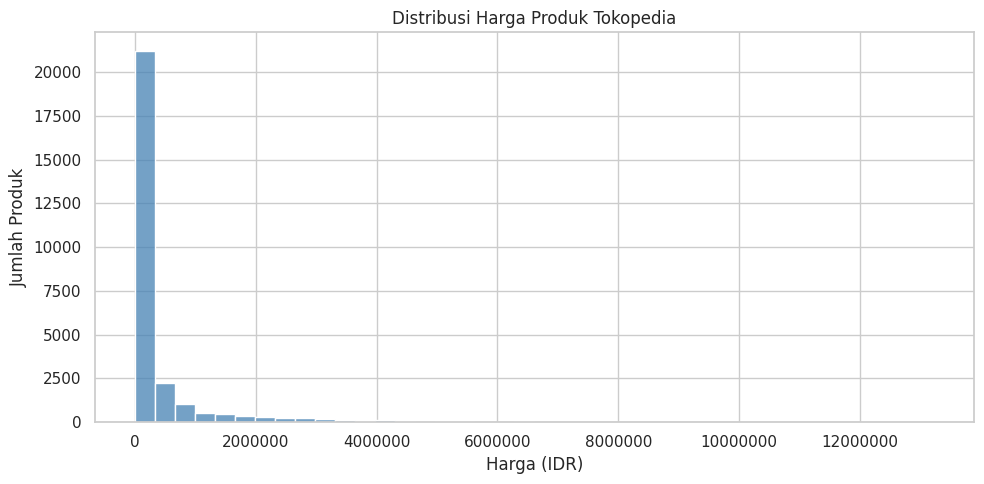

Jumlah produk dengan harga valid: 28020
Median harga: Rp 99,000
Persentil ke-99: Rp 13,222,500
Harga di atas persentil ke-99 (tetap disimpan): 280


In [ ]:
# Histogram distribusi harga
harga_valid = df_clean["Harga (IDR)"].dropna()
batas_harga_p99 = harga_valid.quantile(0.99)
harga_tampilan = harga_valid[ harga_valid <= batas_harga_p99 ]

plt.figure(figsize=(10, 5))
sns.histplot(harga_tampilan, bins=40, color="steelblue")
plt.title("Distribusi Harga Produk Tokopedia")
plt.xlabel("Harga (IDR)")
plt.ylabel("Jumlah Produk")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

print("Jumlah produk dengan harga valid:", len(harga_valid))
print("Median harga: Rp", f"{harga_valid.median():,.0f}")
print("Persentil ke-99: Rp", f"{batas_harga_p99:,.0f}")
print("Harga di atas persentil ke-99 (tetap disimpan):",
      int((harga_valid > batas_harga_p99).sum()))

**Cara membaca:** jika batang menumpuk di sisi kiri dan ada ekor panjang ke kanan, distribusi harga menceng ke kanan. Artinya, banyak produk berada pada harga relatif lebih rendah, sementara hanya sebagian kecil produk berharga sangat tinggi. Kesimpulan akhir harus mengikuti grafik yang benar-benar muncul.

# 9. Top 10 Produk Berdasarkan Penjualan


Jumlah produk: 10


,Nama Produk,Nama Toko,Terjual,Terjual_Teks_Asli
26734,Botol Kale 250 ml EKONOMIS - Botol Plastik 250ml / 250 ml,Grosir Botol Plastik,1000000.0,1jt+ terjual
26739,Botol Almond 250 ml - Botol Plastik 250ml,Plastik Opp Berlian 90,1000000.0,1jt+ terjual
1572,The Originote Ceramella Sunscreen SPF 50 PA+++ Sunblock Mencerahkan Wajah,The Originote_NEW,1000000.0,1jt+ terjual
15694,Dimsum Mix isi 100 pcs Bolekaka Dimsum,Bolekaka Dimsum,1000000.0,1jt+ terjual
9757,Isi 100 Pcs Sendok Garpu Set Hitam Plastik MR,Tokopedia Seller,1000000.0,1jt+ terjual
21543,Hijab Segi Empat Paris Jadul Terlengkap dan Termurah / Jilbab Paris Jadul Old Legend Kerudung Mu...,ARAZYA HIJAB,1000000.0,1jt+ terjual
7226,L'Oreal Paris Voluminous Lash Paradise Waterproof Mascara,L'Oreal Paris Official Store,1000000.0,1jt+ terjual
25515,KAOS POLOS PRIA COTTON COMBED 30S - KAOS LENGAN PENDEK PRIA ROUND NECK REGULER FIT,Distro Bandung Murah,1000000.0,1jt+ terjual
13940,The Originote Hyalucera Moisturizer Gel Ceramide Hyaluronic Muka Wajah Pelembab,The Originote_NEW,1000000.0,1jt+ terjual
13944,Skintific 5X Ceramide Barrier Repair Moisturizer Gel 30gr,Skintific Official Store,1000000.0,1jt+ terjual


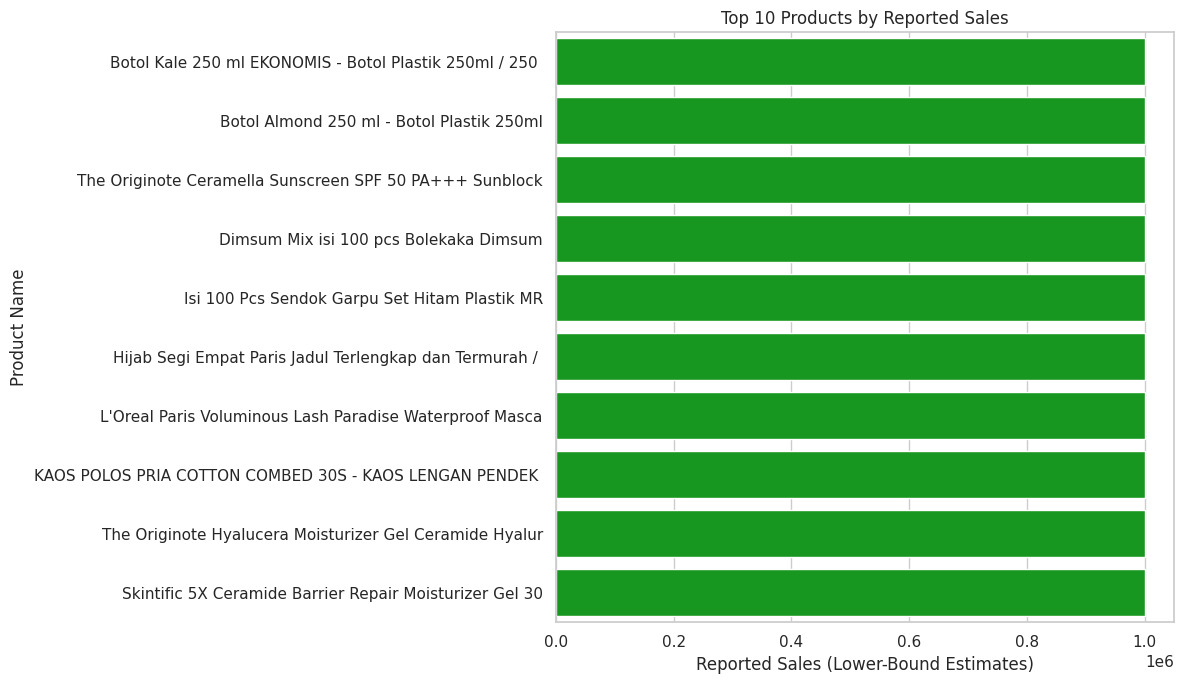

In [35]:
top10 = (
    df_clean
    .dropna(subset=["Terjual"])
    .sort_values(by="Terjual", ascending=False)
    .head(10)
    .copy()
)

print("Jumlah produk:", len(top10))

display(
    top10[
        ["Nama Produk", "Nama Toko", "Terjual", "Terjual_Teks_Asli"]
    ]
)
top10["Nama Produk Singkat"] = (
    top10["Nama Produk"].astype(str).str.slice(0, 55)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x="Terjual",
    y="Nama Produk Singkat",
    color="#03AC0E"
)

plt.title("Top 10 Products by Reported Sales")
plt.xlabel("Reported Sales (Lower-Bound Estimates)")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

## 10. Distribusi diskon dan rating

Diagram ini membantu menjelaskan profil produk secara umum.

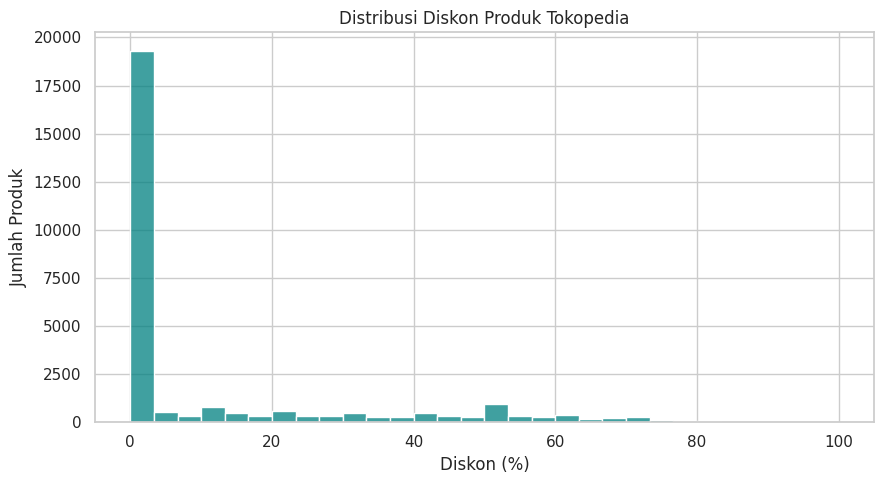

In [ ]:
# Distribusi diskon
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="Diskon (%)", bins=30, color="teal")
plt.title("Distribusi Diskon Produk Tokopedia")
plt.xlabel("Diskon (%)")
plt.ylabel("Jumlah Produk")
plt.tight_layout()
plt.show()

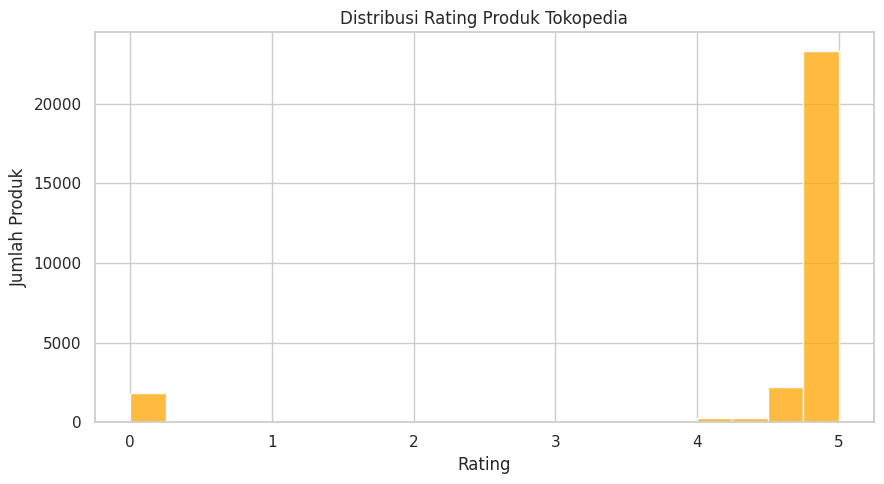

In [ ]:
# Distribusi rating
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="Rating", bins=20, color="orange")
plt.title("Distribusi Rating Produk Tokopedia")
plt.xlabel("Rating")
plt.ylabel("Jumlah Produk")
plt.tight_layout()
plt.show()

# 11. Diagnostic Analytics (Why did it happen?)
Analisis diagnostik mencari pola hubungan antarvariabel. Korelasi mengukur hubungan linear, bukan membuktikan sebab-akibat.

## Diagram 3 : Correlation Heatmap

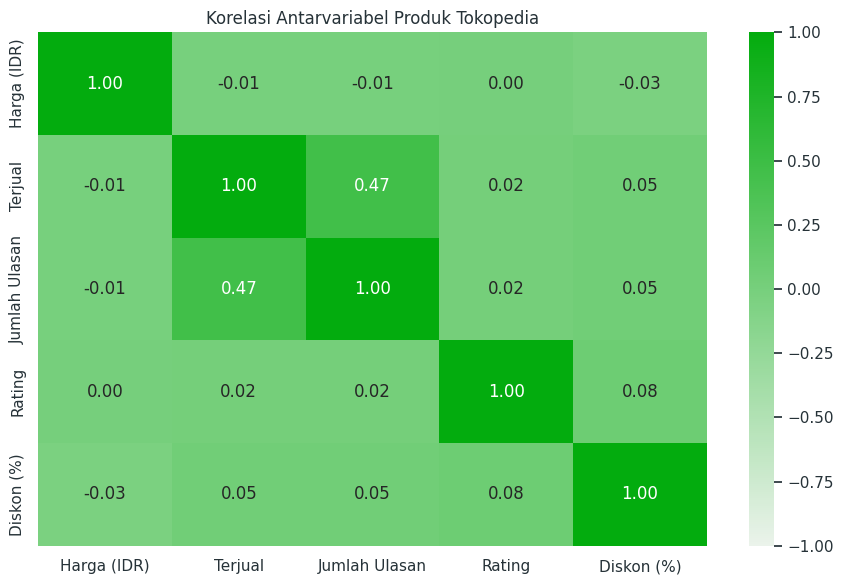

Korelasi terhadap jumlah terjual:


,Korelasi dengan Terjual
Terjual,1.000000
Jumlah Ulasan,0.466946
Diskon (%),0.051721
Rating,0.020357
Harga (IDR),-0.006326


In [ ]:
#Correlation heatmap
kolom_korelasi = [
    "Harga (IDR)", "Terjual", "Jumlah Ulasan", "Rating", "Diskon (%)"
]

korelasi = df_clean[kolom_korelasi].corr(method="pearson")

plt.figure(figsize=(9, 6))
sns.heatmap(
    korelasi,
    annot=True,
    cmap=sns.light_palette("#03AC0E", as_cmap=True),
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Korelasi Antarvariabel Produk Tokopedia")
plt.tight_layout()
plt.show()

print("Korelasi terhadap jumlah terjual:")
display(korelasi["Terjual"].sort_values(ascending=False).to_frame("Korelasi dengan Terjual"))

**Interpretasi:** nilai mendekati +1 menunjukkan hubungan linear positif; mendekati -1 menunjukkan hubungan linear negatif; mendekati 0 menunjukkan hubungan linear lemah.

## Diagram 4 : Scatter Plot Diskon vs Terjual

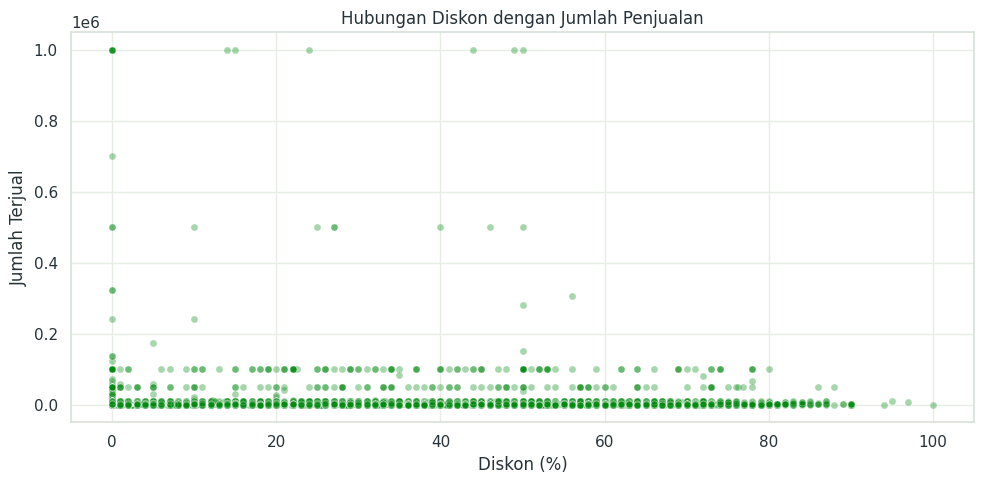

Jumlah produk pada scatter plot: 27829
Korelasi diskon-terjual: 0.052


In [ ]:
# Scatter plot diskon vs penjualan
data_scatter = df_clean.dropna(subset=["Diskon (%)", "Terjual"]).copy()

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=data_scatter,
    x="Diskon (%)",
    y="Terjual",
    alpha=0.35,
    s=25
)
plt.title("Hubungan Diskon dengan Jumlah Penjualan")
plt.xlabel("Diskon (%)")
plt.ylabel("Jumlah Terjual")
plt.tight_layout()
plt.show()

print("Jumlah produk pada scatter plot:", len(data_scatter))
print("Korelasi diskon-terjual:",
      round(data_scatter["Diskon (%)"].corr(data_scatter["Terjual"]), 3))

# 11. Predictive Analytics (What will happen?)

Tugas meminta spektrum prediktif dengan machine learning dan metrik evaluasi. Karena dataset ini berupa snapshot produk, tidak memiliki tanggal dan rangkaian penjualan per periode, model di bawah **mengestimasi jumlah terjual dari karakteristik produk**, bukan meramalkan penjualan bulan depan. Batasan ini harus ditulis pada laporan/infografis agar klaim ilmiah tetap akurat.

Kita menggunakan Random Forest Regression karena target `Terjual` berbentuk angka. Data dibagi menjadi data latih dan data uji. Missing pada fitur prediktor diisi dengan median melalui pipeline yang dipelajari hanya dari data latih.

In [ ]:
data_model = df_clean.dropna(subset=["Terjual"]).copy()

fitur_model = [
    "Harga (IDR)",
    "Jumlah Ulasan",
    "Rating",
    "Diskon (%)"
]

X = data_model[fitur_model].copy()
y = data_model["Terjual"].clip(lower=0)
.
for col in ["Harga (IDR)", "Jumlah Ulasan"]:
    X[col] = np.log1p(X[col].clip(lower=0))

print("Jumlah baris untuk model:", len(X))
print("Missing pada fitur sebelum imputasi:")
display(X.isna().sum().to_frame("Missing"))

Jumlah baris untuk model: 27838
Missing pada fitur sebelum imputasi:


,Missing
Harga (IDR),38
Jumlah Ulasan,1361
Rating,45
Diskon (%),9


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (22270, 4)
Data uji: (5568, 4)


In [ ]:
#Membuat pipeline imputasi dan Random Forest Regression
model_regresi = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

model_regresi.fit(X_train, y_train)
prediksi = model_regresi.predict(X_test)

print("Model selesai dilatih.")

Model selesai dilatih.


In [ ]:
mae = mean_absolute_error(y_test, prediksi)
rmse = np.sqrt(mean_squared_error(y_test, prediksi))
r2 = r2_score(y_test, prediksi)

evaluasi_model = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R-squared"],
    "Nilai": [mae, rmse, r2],
    "Makna": [
        "Rata-rata besar kesalahan estimasi dalam satuan penjualan",
        "Akar rata-rata kuadrat kesalahan; lebih sensitif terhadap kesalahan besar",
        "Proporsi variasi target yang dijelaskan model; dapat bernilai negatif"
    ]
})

display(evaluasi_model.round(3))

,Metrik,Nilai,Makna
0,MAE,2471.178,Rata-rata besar kesalahan estimasi dalam satuan penjualan
1,RMSE,19782.217,Akar rata-rata kuadrat kesalahan; lebih sensitif terhadap kesalahan besar
2,R-squared,-0.029,Proporsi variasi target yang dijelaskan model; dapat bernilai negatif


**Keterangan:**
- MAE: rata-rata selisih absolut antara penjualan aktual dan estimasi. Satuan sama dengan jumlah terjual.
- RMSE: memberi penalti lebih besar pada kesalahan yang besar.
- R-squared: menunjukkan seberapa jauh model menjelaskan variasi target pada data uji. Nilai negatif berarti model lebih buruk daripada baseline rata-rata untuk data uji.


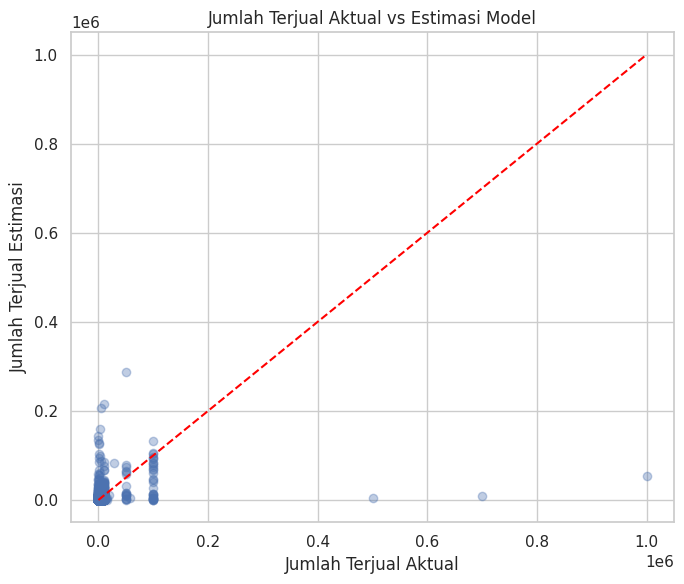

In [ ]:
# Grafik aktual vs prediksi
plt.figure(figsize=(7, 6))
plt.scatter(y_test, prediksi, alpha=0.35)

nilai_maks = max(float(y_test.max()), float(np.max(prediksi)))
plt.plot([0, nilai_maks], [0, nilai_maks], linestyle="--", color="red")

plt.title("Jumlah Terjual Aktual vs Estimasi Model")
plt.xlabel("Jumlah Terjual Aktual")
plt.ylabel("Jumlah Terjual Estimasi")
plt.tight_layout()
plt.show()

# 12. Data Mining: K-Means Clustering (segmentasi)

K-Means mengelompokkan produk berdasarkan kemiripan harga, penjualan, ulasan, rating, dan diskon.
Clustering adalah segmentasi/unsupervised learning, bukan ramalan temporal.
Bagian ini melengkapi model regresi dengan pengelompokan produk untuk menyusun strategi yang berbeda per segmen.

In [ ]:
#clustering
fitur_cluster = [
    "Harga (IDR)",
    "Terjual",
    "Jumlah Ulasan",
    "Rating",
    "Diskon (%)"
]

data_cluster = df_clean[["Nama Produk"] + fitur_cluster].copy()

for col in ["Harga (IDR)", "Terjual", "Jumlah Ulasan"]:
    data_cluster[col] = np.log1p(data_cluster[col].clip(lower=0))

imputer_cluster = SimpleImputer(strategy="median")
X_cluster_imputed = imputer_cluster.fit_transform(data_cluster[fitur_cluster])

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster_imputed)

print("Jumlah produk untuk clustering:", X_cluster_scaled.shape[0])
print("Jumlah fitur:", X_cluster_scaled.shape[1])

Jumlah produk untuk clustering: 28063
Jumlah fitur: 5


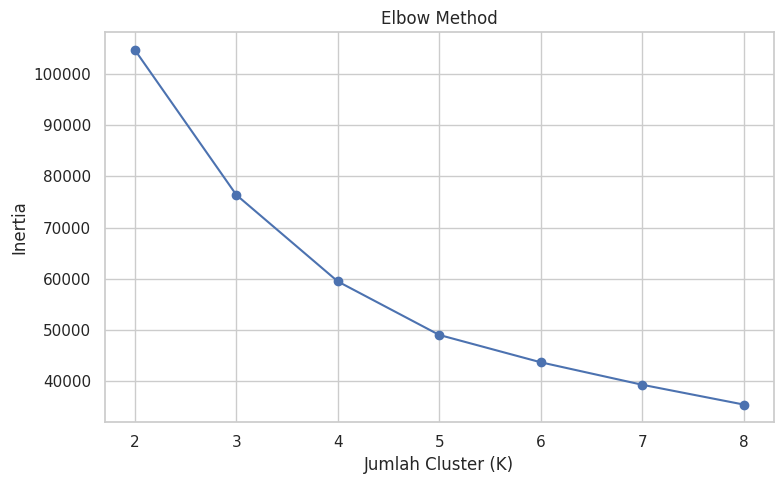

In [ ]:
#Elbow Method untuk melihat kandidat jumlah cluster
daftar_k = range(2, 9)
inertia_values = []

for k in daftar_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertia_values.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(daftar_k), inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(daftar_k))
plt.tight_layout()
plt.show()

,K,Silhouette Score
0,2,0.2531
1,3,0.3203
2,4,0.3213
3,5,0.2940
4,6,0.2803
5,7,0.2772


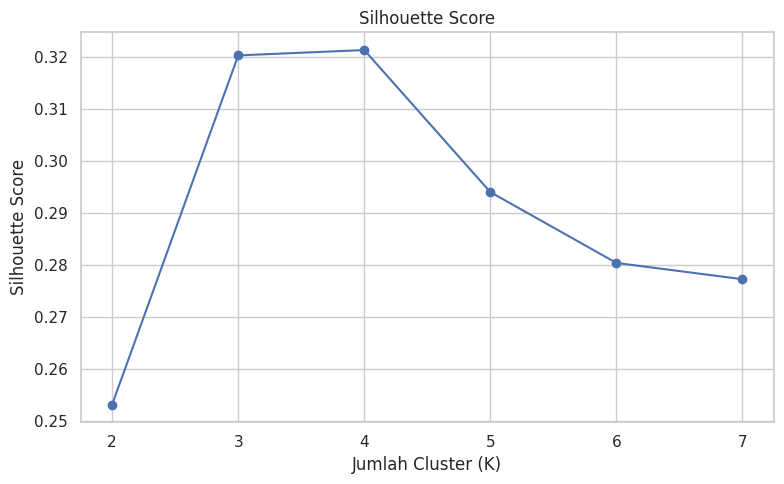

In [ ]:
#Silhouette Score membandingkan kandidat K
hasil_silhouette = []

for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_cluster_scaled)

    score = silhouette_score(
        X_cluster_scaled,
        labels_k,
        sample_size=min(3000, len(X_cluster_scaled)),
        random_state=42
    )

    hasil_silhouette.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(hasil_silhouette)
display(silhouette_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)
plt.title("Silhouette Score")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(silhouette_df["K"])
plt.tight_layout()
plt.show()

In [ ]:
final_k = 4

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

label_cluster = kmeans_final.fit_predict(X_cluster_scaled)

df_hasil_cluster = df_clean.copy()
df_hasil_cluster["Cluster"] = label_cluster

print("Jumlah produk yang berhasil dikelompokkan:", len(df_hasil_cluster))
print("Jumlah cluster:", df_hasil_cluster["Cluster"].nunique())

Jumlah produk yang berhasil dikelompokkan: 28063
Jumlah cluster: 4


In [ ]:
profil_cluster = df_hasil_cluster.groupby("Cluster").agg(
    Jumlah_Produk=("Nama Produk", "count"),
    Median_Harga=("Harga (IDR)", "median"),
    Median_Terjual=("Terjual", "median"),
    Rata_Rating=("Rating", "mean"),
    Median_Ulasan=("Jumlah Ulasan", "median"),
    Rata_Diskon=("Diskon (%)", "mean")
).round(2)

profil_cluster["Persentase (%)"] = (
    profil_cluster["Jumlah_Produk"] /
    profil_cluster["Jumlah_Produk"].sum() * 100
).round(2)

display(profil_cluster)

,Jumlah_Produk,Median_Harga,Median_Terjual,Rata_Rating,Median_Ulasan,Rata_Diskon,Persentase (%)
Cluster,,,,,,,
0,8853,43800.0,500.0,4.88,100.0,3.94,31.55
1,1847,108999.5,0.0,0.01,0.0,3.23,6.58
2,12689,224930.0,10.0,4.94,2.0,2.60,45.22
3,4674,77900.0,100.0,4.85,30.0,52.34,16.66


## Grafik 5 : Pie Chart Distribusi Cluster
Pie chart menunjukkan proporsi produk di setiap cluster.

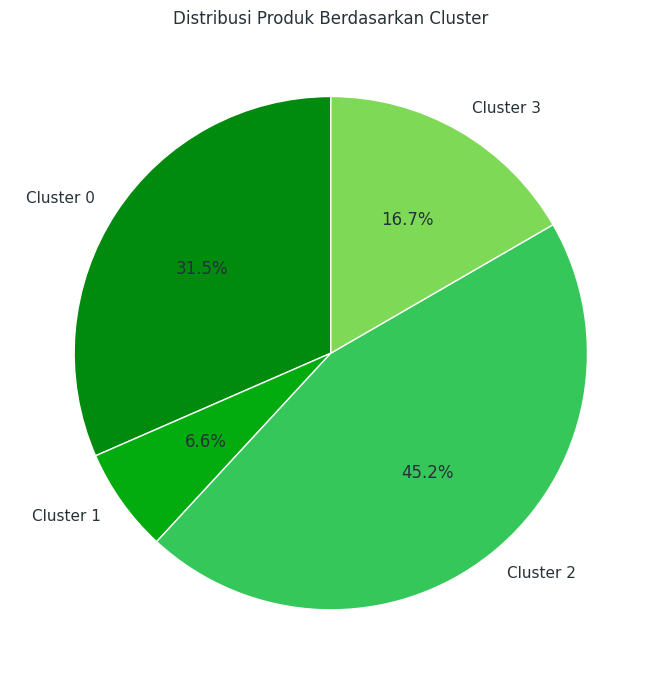

In [ ]:
jumlah_per_cluster = df_hasil_cluster["Cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 7))
plt.pie(
    jumlah_per_cluster.values,
    labels=[f"Cluster {i}" for i in jumlah_per_cluster.index],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribusi Produk Berdasarkan Cluster")
plt.tight_layout()
plt.show()

## Grafik 6 : Median Penjualan per Cluster
Median dipakai karena jumlah terjual memiliki nilai ekstrem. Median lebih tahan terhadap nilai ekstrem dibandingkan rata-rata.

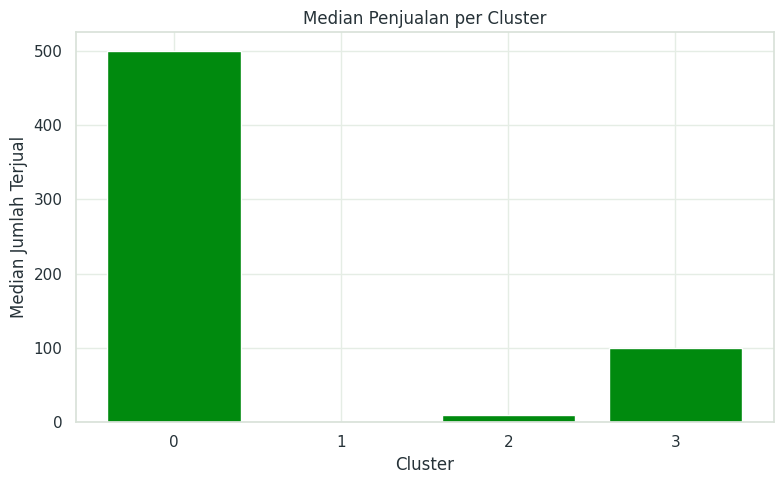

,Jumlah_Produk,Persentase (%),Median_Terjual
Cluster,,,
0,8853,31.55,500.0
1,1847,6.58,0.0
2,12689,45.22,10.0
3,4674,16.66,100.0


In [ ]:
#Bar chart median penjualan per cluster
plt.figure(figsize=(8, 5))
plt.bar(
    profil_cluster.index.astype(str),
    profil_cluster["Median_Terjual"]
)
palette={
        0: "#008A0E",
        1: "#B7E4A8",
        2: "#7ED957",
        3: "#03AC0E"
    },
plt.title("Median Penjualan per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Jumlah Terjual")
plt.tight_layout()
plt.show()

display(profil_cluster[["Jumlah_Produk", "Persentase (%)", "Median_Terjual"]])

# 13. Prescriptive Analytics (What should we do?)


In [ ]:
# K1. Membuat rekomendasi berbasis profil aktual
median_penjualan_global = df_hasil_cluster["Terjual"].median()
median_diskon_global = df_hasil_cluster["Diskon (%)"].median()
median_rating_global = df_hasil_cluster["Rating"].median()

def rekomendasi_cluster(row):
    median_sales = row["Median_Terjual"]
    avg_discount = row["Rata_Diskon"]
    avg_rating = row["Rata_Rating"]

    if pd.notna(median_sales) and median_sales >= median_penjualan_global:
        if pd.notna(avg_discount) and avg_discount > median_diskon_global:
            return "Pertahankan penjualan, tetapi evaluasi diskon dan margin."
        return "Pertahankan stok, kualitas produk, dan pelayanan."

    if pd.notna(avg_rating) and avg_rating >= median_rating_global:
        return "Uji peningkatan visibilitas, konten, dan promosi terarah."

    return "Evaluasi harga, foto, deskripsi, ulasan, dan kepercayaan pelanggan."


profil_rekomendasi = profil_cluster.copy()
profil_rekomendasi["Rekomendasi Strategi"] = profil_rekomendasi.apply(
    rekomendasi_cluster,
    axis=1
)

display(profil_rekomendasi)

,Jumlah_Produk,Median_Harga,Median_Terjual,Rata_Rating,Median_Ulasan,Rata_Diskon,Persentase (%),Rekomendasi Strategi
Cluster,,,,,,,,
0,8853,43800.0,500.0,4.88,100.0,3.94,31.55,"Pertahankan penjualan, tetapi evaluasi diskon dan margin."
1,1847,108999.5,0.0,0.01,0.0,3.23,6.58,"Evaluasi harga, foto, deskripsi, ulasan, dan kepercayaan pelanggan."
2,12689,224930.0,10.0,4.94,2.0,2.60,45.22,"Evaluasi harga, foto, deskripsi, ulasan, dan kepercayaan pelanggan."
3,4674,77900.0,100.0,4.85,30.0,52.34,16.66,"Pertahankan penjualan, tetapi evaluasi diskon dan margin."


**Cara mengambil keputusan bisnis:**
- Cluster dengan median penjualan tinggi: prioritaskan ketersediaan stok, kualitas, dan layanan. Jangan otomatis menambah diskon.
- Cluster dengan penjualan rendah tetapi rating relatif tinggi: uji visibilitas, konten produk, dan promosi yang terukur.
- Cluster dengan penjualan dan rating rendah: evaluasi foto, deskripsi, harga, layanan, dan ulasan.
- Cluster dengan diskon tinggi: evaluasi efektivitas promosi dan margin. Dataset ini tidak memiliki data margin, jadi jangan mengklaim peningkatan profit secara pasti.

# 14. Ringkasan angka untuk infografis


In [38]:
if "df" not in globals():
    raise NameError(
        "Variabel df belum tersedia. Jalankan kembali proses cleaning."
    )

df_clean = df.copy()

print("Dataset berhasil disiapkan.")
print("Jumlah data mentah:", len(df_raw))
print("Jumlah data bersih:", len(df_clean))

display(df_clean.head())

Dataset berhasil disiapkan.
Jumlah data mentah: 29519
Jumlah data bersih: 29519


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Terjual_Teks_Asli,Ulasan_Teks_Asli
0,Raw Food Beef Bone-In / Daging Giling / Dog Food / Cat Food,Lazy Dog Supply,Jakarta Selatan,1000.0,10.0,50.0,35000.0,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-food-beef-bone-in-daging-giling-dog-food-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1rb+ terjual,10 ulasan
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun Raw Dog Cat Food,RumahBully,Jakarta Timur,250.0,NaN,50.0,79999.0,0.0,https://www.tokopedia.com/rumahbully/turkey-meat-only-no-bone-1kg-daging-kalkun-raw-dog-cat-food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,250+ terjual,NaN
2,Chicken mix Salmon Raw Food ayam mix salmon makanan kucing anjing dog food 1kg omega3,RumahBully,Jakarta Barat,26.0,NaN,50.0,33000.0,0.0,https://www.tokopedia.com/rumahbully/chicken-mix-salmon-raw-food-ayam-mix-salmon-makanan-kucing-...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26 terjual,NaN
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG FOOD 1KG,RumahBully,Tangerang Selatan,100.0,NaN,50.0,29900.0,0.0,https://www.tokopedia.com/rumahbully/promo-bulanan-sosis-chop-premium-raw-dog-food-1kg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100+ terjual,NaN
4,Premium Dog Food / Daging Sapi Giling / Raw Food Beef Bone-In PLUS 1KG,RumahBully,Jakarta Selatan,1000.0,NaN,50.0,39000.0,0.0,https://www.tokopedia.com/rumahbully/premium-dog-food-daging-sapi-giling-raw-food-beef-bone-in-p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1rb+ terjual,NaN
